**Hand-off adapter (Cell 0).** Topic 3 produced `data/processed/prepared_text.jsonl`, while this lab expects `prepared_chunks.jsonl` and `chunks.pkl`. Cell 0 converts each Topic 3 record into a LangChain `Document`, keeps all Topic 3 fields as metadata and writes both files. The text is not changed.

In [ ]:
# Cell 0 — Topic 3 -> Topic 4 hand-off adapter
# Lab 4 expects prepared_chunks.jsonl + chunks.pkl, but the Topic 3 lab produced
# data/processed/prepared_text.jsonl. This cell converts it without changing any text.
!pip install -q langchain-core
import json, pickle
from langchain_core.documents import Document

SRC = '/content/prepared_text.jsonl'
records = [json.loads(l) for l in open(SRC, encoding='utf-8') if l.strip()]

chunks = [Document(page_content=r['text'],
                   metadata={'record_id': r['record_id'], 'source': r['source'],
                             'source_sha256': r['source_sha256'],
                             'processing': r['processing'], 'page': r['page']})
          for r in records]

with open('/content/prepared_chunks.jsonl', 'w', encoding='utf-8') as f:
    for i, c in enumerate(chunks):
        f.write(json.dumps({'chunk_id': i, 'text': c.page_content, 'metadata': c.metadata},
                           ensure_ascii=False) + '\n')
with open('/content/chunks.pkl', 'wb') as f:
    pickle.dump(chunks, f)

print('Week 3 records read:', len(records))

Week 3 records read: 26


# **Part A - Assess and Validate Your Prepared Data**

## **Step A0:** Plan your data quality gate

The quality gate starts from what the data must provide for two Topic 2 requirements to be achievable, rather than from the validation rules that could be written.

| Topic 2 requirement | Required data / evidence | Quality concern | Observable check | Possible decision |
|---|---|---|---|---|
| **FR3 / RAI5:** provide the original supporting sentence from the official source, with the source reference and last-checked date; flag rules past the 90-day review period | Complete official sentences for each procedural rule, with source file, SHA-256 hash and retrieval date; fee tables with their row and column labels | Accuracy, consistency, timeliness | Key rule sentences are complete; no corrupted or private-use characters; source and hash match the Topic 3 manifest; fee tables keep their structure; time-sensitive statements (years, price updates) are flagged | Accept / Correct / Review |
| **FR2 / RAI1:** list all requirements that apply to the destination, activity and traveller category, with no more than a 10-point recall gap between Malaysian and international travellers | At least one official source for each V1 site; fees and rules stated for both traveller categories | Completeness | Each V1 site (Mount Kinabalu, Sipadan, Tunku Abdul Rahman Marine Park) has at least one official source; each fee can be read unambiguously for both Malaysian and international climbers | GO with conditions / Hold affected sites |

## **Step A1:** Load and verify the Topic 3 prepared-data hand-off


In [ ]:
# Cell 1 — Topic 4 setup and Topic 3 hand-off verification
!pip install -q pandera pandas matplotlib

import os, re, json, pickle, hashlib
import pandas as pd
import matplotlib.pyplot as plt
import pandera.pandas as pa

with open('/content/chunks.pkl', 'rb') as f:
	chunks = pickle.load(f)

prepared_records = []
with open('/content/prepared_chunks.jsonl', 'r', encoding='utf-8') as f:
  for line in f:
    if line.strip():
      prepared_records.append(json.loads(line))

print(f'Compatibility chunks: {len(chunks)}')
print(f'Inspectable JSONL records: {len(prepared_records)}')

if len(chunks) != len(prepared_records):
	raise ValueError('Topic 3 hand-off mismatch: JSONL and PKL chunk counts differ.')

print('Topic 3 hand-off verified.')
print(chunks[0].page_content[:250])
print(chunks[0].metadata)

Compatibility chunks: 26
Inspectable JSONL records: 26
Topic 3 hand-off verified.
Choose a hostel How to book Get ready Your itinerary Fees & changes Climb safely L E M A I N G & P A N A L A B A N · 2 D A Y S / 1 N I G H T Your Mount Kinabalu

climbing guide

Choose your hostel. Book your climb. Arrive prepared.

Book your climb


{'record_id': 'sabahparks_mount_kinabalu_climbing-0001', 'source': 'sabahparks_mount_kinabalu_climbing.pdf', 'source_sha256': 'e44c77e57554c6513f811addd11e53f6b7c61cb6747880def4f655876c8e6fc7', 'processing': 'paragraph-aware-char-500 (cookie banner removed, paragraphs restored)', 'page': None}


## **Step A2:** Build a quality inventory for missing, corrupted, and noisy data

In [ ]:
# Cell 2 — Build a chunk-quality inventory (lab fields + project-specific fields)
import re, unicodedata
import pandas as pd

# From docs/week3_data_inventory.md (S01-S03) and data/week3_manifest.json
INVENTORY_SOURCES = {'sabahparks_mount_kinabalu_climbing.pdf',
                     'sabahparks_terms_and_conditions.pdf',
                     'gec_haze_safety_advisory.pdf'}
MANIFEST_SHA256 = {'sabahparks_mount_kinabalu_climbing.pdf':
                   'e44c77e57554c6513f811addd11e53f6b7c61cb6747880def4f655876c8e6fc7'}

def has_private_use(t):   # icon-font glyphs such as U+E931 (category 'Co')
    return any(unicodedata.category(ch) == 'Co' for ch in t)

rows = []
for i, chunk in enumerate(chunks):
    text = chunk.page_content or ''
    meta = chunk.metadata or {}
    source = str(meta.get('source', '') or '')
    stripped = text.strip()
    rows.append({
        'chunk_id': i,
        'record_id': meta.get('record_id', ''),
        'source': source,
        'page': meta.get('page', None),
        'text': text,
        'char_count': len(stripped),
        'missing_text': len(stripped) == 0,
        'missing_source': source.strip() == '',
        'corrupted_char': ('\x00' in text) or ('\ufffd' in text),   # lab's original check
        'noisy_whitespace': bool(re.search(r'\n{4,}| {4,}', text)),
        # --- project-specific fields ---
        'in_inventory': source in INVENTORY_SOURCES,
        'hash_matches_manifest': meta.get('source_sha256') == MANIFEST_SHA256.get(source),
        'private_use_char': has_private_use(text),
        'letter_spaced_heading': bool(re.search(r'(?:\b\w ){4,}\w\b', text)),
        'time_sensitive': bool(re.search(r'\b20\d\d\b|price update', text, re.I)),
        'mentions_international': 'international' in text.lower(),
    })
df = pd.DataFrame(rows)
df['has_bad_char'] = df['corrupted_char'] | df['private_use_char']   # used by Cell 4

print(df[['chunk_id','char_count','missing_text','missing_source',
          'corrupted_char','private_use_char','letter_spaced_heading']].head())
print(df['char_count'].describe())
print('Missing text:', int(df['missing_text'].sum()))
print('Missing source metadata:', int(df['missing_source'].sum()))
print('Possible corrupted text (lab check: \\x00 / replacement char):', int(df['corrupted_char'].sum()))
print('Possible noisy whitespace:', int(df['noisy_whitespace'].sum()))
print('--- Project-specific checks ---')
print('Source not in inventory:', int((~df['in_inventory']).sum()))
print('Source hash does not match manifest:', int((~df['hash_matches_manifest']).sum()))
print('Private-use icon characters (e.g. U+E931):', int(df['private_use_char'].sum()))
print('Letter-spaced headings:', int(df['letter_spaced_heading'].sum()))
print('Time-sensitive chunks (years / price updates):', int(df['time_sensitive'].sum()),
      list(df.loc[df['time_sensitive'], 'chunk_id']))
print('Chunks mentioning international travellers:', int(df['mentions_international'].sum()))

   chunk_id  char_count  missing_text  missing_source  corrupted_char  \
0         0         269         False           False           False   
1         1         494         False           False           False   
2         2         499         False           False           False   
3         3         463         False           False           False   
4         4         372         False           False           False   

   private_use_char  letter_spaced_heading  
0             False                   True  
1             False                   True  
2              True                  False  
3             False                  False  
4              True                   True  
count     26.000000
mean     418.576923
std       86.378781
min      123.000000
25%      379.500000
50%      443.000000
75%      480.500000
max      499.000000
Name: char_count, dtype: float64
Missing text: 0
Missing source metadata: 0
Possible corrupted text (lab check: \x00 / replacement 

## **Step A3:** Manual inspection using the five quality dimensions

In [ ]:
# Cell 3 — Manual inspection: lab's random sample + targeted cases found during profiling
def show(t):   # make invisible icon-font glyphs visible
    return ''.join(f'⟨U+{ord(ch):04X}⟩' if unicodedata.category(ch) == 'Co' else ch for ch in t)

sample_ids = list(df.sample(min(10, len(df)), random_state=42)['chunk_id'])
targeted_ids = [2, 3, 25]   # fee tables (2, 3) and the short footer (25)
print('Random sample:', sorted(sample_ids), '| Targeted:', targeted_ids)

for idx in sorted(set(sample_ids) | set(targeted_ids)):
    c = chunks[int(idx)]
    tag = 'TARGETED' if idx in targeted_ids else 'RANDOM'
    print(f'\n--- CHUNK {idx} ({tag}) ---')
    print('Source:', c.metadata.get('source', '?'), '| Page:', c.metadata.get('page', '?'))
    print(show(c.page_content[:1200]))

Random sample: [0, 1, 5, 8, 9, 11, 13, 16, 23, 24] | Targeted: [2, 3, 25]

--- CHUNK 0 (RANDOM) ---
Source: sabahparks_mount_kinabalu_climbing.pdf | Page: None
Choose a hostel How to book Get ready Your itinerary Fees & changes Climb safely L E M A I N G & P A N A L A B A N · 2 D A Y S / 1 N I G H T Your Mount Kinabalu

climbing guide

Choose your hostel. Book your climb. Arrive prepared.

Book your climb

2027 Booking Status

--- CHUNK 1 (RANDOM) ---
Source: sabahparks_mount_kinabalu_climbing.pdf | Page: None
As of 19 September 2026, bookings for the 2027 Mount Kinabalu climbing season have not opened. Availability for any climbing date in 2027 cannot yet be confirmed. This does not mean that the dates are fully booked. Please check the official booking website for opening announcements.

2026 climbing season

January–December 2026 bookings opened on 1 December 2025 at 1:00 am. Reservations are online only and subject to available slots.

S T A R T W I T H T H E R I G H T S T A Y Host

**A3 observations**

| Observation | Classification / quality concern | Evidence needed | Decision |
|---|---|---|---|
| The hostel fee tables are flattened in chunks 2–3: "RM" and each amount are on separate lines, the column labels (18 & above, 17 & below) are far from the amounts, and the Panalaban table is split across two chunks, with its International row only in chunk 3 | Accuracy and completeness; RAI1 risk, because the international fees can no longer be read reliably | Compare with the tables on the original web page | Correct (re-extract the tables from the web page) |
| An invisible character U+E931 appears in 10 chunks | Corrupted — an icon-font glyph from the web page, not detected by the lab check for U+FFFD | Unicode category Co; position matches an icon on the page | Correct (strip) |
| Chunk 25 (123 characters) contains only "Stay connected with our parks", "Web Visitor Statistics" and the copyright line | Noisy boilerplate (page footer) | Compare with the page footer; the "Last Updated" date is already stored in the manifest | Remove |
| Chunk 1 states that "As of 19 September 2026, bookings for the 2027 Mount Kinabalu climbing season have not opened" | Timeliness — accurate now but will become stale | Retrieval date and the official booking announcements | Retain, flagged as time-sensitive |
| Headings are cut from their content at chunk boundaries, e.g. "Dinner" ends chunk 11 while "Dinner is served at Laban Rata Resthouse" starts chunk 12; "2027 Booking Status" ends chunk 0 | Completeness and consistency — a retrieved chunk may contain a heading without its rule, or a rule without its heading | Compare chunk boundaries with the page sections | Review (record now; fix with heading-aware chunking) |

**Reflection.** The issue that would be hardest to express as a simple numeric or format rule is the flattened fee table. Each chunk on its own passes every structural check: the text is present, the source is traceable, the length is normal and the characters are valid. The defect only becomes visible when the chunk is read against the original table, because the problem is the relationship between values, not any single value. The amount "RM 1,043.25" is still in the text, but the system can no longer tell that it is the price for an international climber aged 18 and above at Panalaban Hostel. This affects accuracy and completeness, and it is also a fairness risk under RAI1, because the international fees are the ones most affected. A per-chunk rule cannot detect this because it checks one chunk at a time, while the table was spread across two chunks. In contrast, the private-use character was also first found manually, but once found it could be turned into a repeatable rule (R5), because it is a property of individual characters.

## **Step A4:** Define and run at least three validation rules with Pandera

In [ ]:
# Cell 4 — Repeatable validation rules (project-specific)
import os
import pandera.pandas as pa

MIN_CHARS = 200   # all content chunks observed are >= 269 chars; shorter = likely fragment/footer

# R7 helper: does the chunk END with a short heading/label whose content is in the next chunk?
def ends_with_split_heading(text):
    last = text.strip().split('\n\n')[-1].strip()
    return len(last) < 60 and not re.search(r'[.!?)]$', last)
df['split_heading_end'] = [ends_with_split_heading(t) for t in df['text']]
df.loc[df.index[-1], 'split_heading_end'] = False   # last chunk has no next chunk

schema = pa.DataFrameSchema({
    'text': pa.Column(str, pa.Check(lambda s: s.str.strip().str.len() > 0,
                      error='R1 chunk text must not be empty'), nullable=False),
    'in_inventory': pa.Column(bool, pa.Check(lambda s: s,
                      error='R2 source must be an inventoried source (S01-S03)'), nullable=False),
    'hash_matches_manifest': pa.Column(bool, pa.Check(lambda s: s,
                      error='R3 source SHA-256 must match the Week 3 manifest'), nullable=False),
    'char_count': pa.Column(int, pa.Check.ge(MIN_CHARS,
                      error=f'R4 chunk shorter than {MIN_CHARS} characters'), nullable=False),
    'has_bad_char': pa.Column(bool, pa.Check(lambda s: ~s,
                      error='R5 corrupted or private-use (icon) characters found'), nullable=False),
    'letter_spaced_heading': pa.Column(bool, pa.Check(lambda s: ~s,
                      error='R6 letter-spaced heading noise found'), nullable=False),
    'split_heading_end': pa.Column(bool, pa.Check(lambda s: ~s,
                      error='R7 chunk ends with a heading separated from its content'), nullable=False),
}, strict=False)

DECISION = {'text': 'Hard fail', 'in_inventory': 'Hard fail', 'hash_matches_manifest': 'Hard fail',
            'char_count': 'Manual review', 'has_bad_char': 'Correct',
            'letter_spaced_heading': 'Warning', 'split_heading_end': 'Warning'}
REASON = {
    'text': 'Stop: an empty chunk gives no evidence to cite (FR3)',
    'in_inventory': 'Stop: evidence from an unknown source cannot be traced or verified (FR3)',
    'hash_matches_manifest': 'Stop: the file differs from the recorded version, so its rules must be re-verified (RAI5)',
    'char_count': 'Inspect before deciding: a short chunk may be a footer fragment or a valid short rule',
    'has_bad_char': 'Fix and keep: the icon character carries no meaning and can be removed safely',
    'letter_spaced_heading': 'Record only: decorative label; meaning is kept by the heading that follows',
    'split_heading_end': 'Record only now: fix in pipeline V2 with heading-aware chunking before Week 9',
}

try:
    schema.validate(df, lazy=True)
    failure_cases = pd.DataFrame()
    print('All schema rules passed.')
except pa.errors.SchemaErrors as exc:
    failure_cases = exc.failure_cases.copy()
    failure_cases['chunk_id'] = failure_cases['index']
    failure_cases['record_id'] = failure_cases['index'].map(df['record_id'])
    failure_cases['decision'] = failure_cases['column'].map(DECISION)
    failure_cases['decision_reason'] = failure_cases['column'].map(REASON)
    print(failure_cases[['column', 'check', 'chunk_id', 'decision']].to_string(index=False))

print('\nFailures per rule (out of', len(df), 'chunks):')
summary = failure_cases.groupby(['column', 'decision']).size().reset_index(name='failures')
summary['percent'] = (summary['failures'] / len(df) * 100).round(1)
print(summary.to_string(index=False))

os.makedirs('/content/docs', exist_ok=True)
failure_cases.to_csv('/content/docs/week4_validation_failures.csv', index=False)
print('\nSaved: /content/docs/week4_validation_failures.csv')

               column                                                   check  chunk_id      decision
           char_count                    R4 chunk shorter than 200 characters        25 Manual review
    split_heading_end R7 chunk ends with a heading separated from its content         9       Warning
    split_heading_end R7 chunk ends with a heading separated from its content         0       Warning
    split_heading_end R7 chunk ends with a heading separated from its content         1       Warning
    split_heading_end R7 chunk ends with a heading separated from its content         2       Warning
    split_heading_end R7 chunk ends with a heading separated from its content         3       Warning
    split_heading_end R7 chunk ends with a heading separated from its content         4       Warning
    split_heading_end R7 chunk ends with a heading separated from its content         6       Warning
    split_heading_end R7 chunk ends with a heading separated from its content     

**A4 validation rules**

| Rule | Condition | Why this rule? / failure being detected | Failures | Decision | What the decision means here |
|---|---|---|---|---|---|
| R1 Text present | text is not empty | An empty chunk provides no evidence to cite | 0 | Hard fail | Stop the pipeline; the input must be regenerated in Topic 3 |
| R2 Source in inventory | source is one of the 3 inventoried files | Evidence from an unknown source cannot be verified as official (FR3) | 0 | Hard fail | Stop; an untraceable chunk must not reach the knowledge base |
| R3 Hash matches manifest | source_sha256 equals the Week 3 manifest | The chunk may come from a different version of the file | 0 | Hard fail | Stop; re-run Topic 3 on the correct file version |
| R4 Minimum useful length | char_count ≥ 200 | Fragments too short to hold a complete rule. Every content chunk is at least 269 characters, so 200 separates fragments without failing valid short rules | 1 (3.8%) | Manual review | Inspect the chunk before deciding; a short chunk may still be a valid rule |
| R5 No bad characters | has_bad_char is False | Corrupted or private-use characters from extraction | 10 (38.5%) | Correct | Fix the text automatically and keep the chunk |
| R6 No letter-spaced headings | letter_spaced_heading is False | Headings such as "L E M A I N G" do not match normal search words | 10 (38.5%) | Warning | Record only; the content is still correct and readable |
| R7 No split heading at end | last paragraph is not a short heading (excluding the last chunk) | A heading cut from its content at the chunk boundary | 17 (65.4%) | Warning | Record only; fix through table correction now and heading-aware chunking in V2 |

The R4 threshold was set at 200 rather than the lab's example of 100 because of the evidence in A2: no chunk holding a complete rule was shorter than 269 characters, while the page footer was 123 characters.

**Why R7 fails so often.** The Topic 3 pipeline splits the text into paragraph-aware chunks with a fixed limit of 500 characters. This keeps sentences whole, but the limit is applied without regard to the section structure of the page, so a new chunk can start between a heading and the text it introduces. In the itinerary, chunk 11 ends with "4:30 pm–7:00 pm" and the heading "Dinner", while chunk 12 starts with "Dinner is served at Laban Rata Resthouse (SSL)." followed directly by "2:00 am–3:30 am". If chunk 12 is retrieved on its own, the dinner could be linked to the wrong time. No per-chunk content check can detect this; R7 detects the symptom, and the fix is to chunk by section heading in V2.

## **Step A5:** Review and triage validation failures

**A5 implementation note.** The lab provides a triage table for A5 but no code to apply its decisions, and Cell 5 deduplicates the original chunks. Cells 4B–4E therefore apply the A5 decisions before deduplication, so that the reviewed corpus saved in Cell 5 matches the decisions recorded in this notebook and in the report:

- **Cell 4B** removes the footer chunk and strips the private-use character.
- **Cell 4C** retrieves the official page in its native format (HTML) and archives it with its SHA-256 hash.
- **Cell 4D** verifies every HTML table before use (Check A: each row appears in the Topic 3 text; Check B: breakdown rows sum to the verified package price), with a negative test.
- **Cell 4E** replaces the flattened tables in the chunks with the verified tables.

In [ ]:
# Cell 4B — Apply triage decisions (A5) with provenance recorded in metadata
import copy, unicodedata
from langchain_core.documents import Document

chunks_original = copy.deepcopy(chunks)          # keep the Topic 3 hand-off unchanged for audit
REMOVE_IDS = {25}                                # R4: website footer, no rule content
triage_log = []
triaged = []

for i, c in enumerate(chunks):
    meta = dict(c.metadata)
    meta['review_flags'] = []
    meta['corrections'] = []
    if i in REMOVE_IDS:
        triage_log.append({'chunk_id': i, 'record_id': meta['record_id'], 'action': 'Remove',
                           'rule': 'R4', 'reason': 'Website footer; version date already in Week 3 manifest'})
        continue
    text = c.page_content
    # R5: remove private-use icon-font characters such as U+E931
    n_pua = sum(1 for ch in text if unicodedata.category(ch) == 'Co')
    if n_pua:
        text = ''.join(ch for ch in text if unicodedata.category(ch) != 'Co')
        text = re.sub(r'[ \t]+\n', '\n', text)
        text = re.sub(r'\n{3,}', '\n\n', text).strip()
        meta['corrections'].append(f'R5: removed {n_pua} private-use icon character(s)')
        triage_log.append({'chunk_id': i, 'record_id': meta['record_id'], 'action': 'Correct',
                           'rule': 'R5', 'reason': f'Removed {n_pua} icon-font character(s)'})
    # Warnings retained for later pipeline V2 work (no text change)
    if df.loc[i, 'letter_spaced_heading']:
        meta['review_flags'].append('R6 letter-spaced heading')
    if df.loc[i, 'split_heading_end']:
        meta['review_flags'].append('R7 heading separated from content')
    if df.loc[i, 'time_sensitive']:
        meta['review_flags'].append('time-sensitive: re-verify within 90 days (RAI5)')
    triaged.append(Document(page_content=text, metadata=meta))

chunks = triaged
print('Chunks before triage:', len(chunks_original), '| after triage:', len(chunks))
print(pd.DataFrame(triage_log)[['chunk_id', 'action', 'rule', 'reason']].to_string(index=False))
print('Private-use characters remaining:',
      sum(1 for c in chunks for ch in c.page_content if unicodedata.category(ch) == 'Co'))

Chunks before triage: 26 | after triage: 25
 chunk_id  action rule                                                  reason
        2 Correct   R5                        Removed 1 icon-font character(s)
        4 Correct   R5                        Removed 1 icon-font character(s)
        8 Correct   R5                        Removed 1 icon-font character(s)
       10 Correct   R5                        Removed 1 icon-font character(s)
       14 Correct   R5                        Removed 1 icon-font character(s)
       16 Correct   R5                        Removed 1 icon-font character(s)
       19 Correct   R5                        Removed 1 icon-font character(s)
       22 Correct   R5                        Removed 1 icon-font character(s)
       24 Correct   R5                        Removed 1 icon-font character(s)
       25  Remove   R4 Website footer; version date already in Week 3 manifest
Private-use characters remaining: 0


In [ ]:
# Cell 4C — Read the official page in its native format (HTML) and list its tables
import requests, hashlib, datetime, urllib.robotparser
from io import StringIO

URL = 'https://sabahparks.org.my/services/mount-kinabalu-climbing'
try:
    rp = urllib.robotparser.RobotFileParser('https://sabahparks.org.my/robots.txt')
    rp.read()
    print('Allowed by robots.txt:', rp.can_fetch('*', URL))
except Exception as e:
    print('robots.txt could not be read:', e)

resp = requests.get(URL, headers={'User-Agent': 'Mozilla/5.0 (UTM SAIA3113 student project)'}, timeout=30)
print('HTTP status:', resp.status_code)
html_bytes = resp.content
html_retrieved_at = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec='seconds')
html_sha256 = hashlib.sha256(html_bytes).hexdigest()

os.makedirs('/content/data/raw', exist_ok=True)
with open('/content/data/raw/sabahparks_mount_kinabalu_climbing.html', 'wb') as f:
    f.write(html_bytes)                       # archived HTML snapshot for provenance
print('Retrieved at (UTC):', html_retrieved_at, '| HTML SHA-256:', html_sha256[:16], '...')

try:
    html_tables = pd.read_html(StringIO(resp.text))
except ValueError:
    html_tables = []
print('HTML tables found:', len(html_tables))
for k, t in enumerate(html_tables):
    print(f'\n--- HTML table {k} | shape {t.shape} ---')
    print(t.to_string(index=False)[:700])

Allowed by robots.txt: True
HTTP status: 200
Retrieved at (UTC): 2026-11-25T07:15:17+00:00 | HTML SHA-256: 6c9dd449d1b0ced0 ...
HTML tables found: 6

--- HTML table 0 | shape (1, 3) ---
  Climber 18 & above 17 & below
Malaysian  RM 508.25  RM 454.75

--- HTML table 1 | shape (4, 3) ---
               Included    18+    ≤17
Accommodation & 3 meals 365.00 365.00
        Climbing permit 100.00  50.00
              Insurance  10.00  10.00
    Service charge · 7%  33.25  29.75

--- HTML table 2 | shape (2, 3) ---
      Climber  18 & above 17 & below
    Malaysian   RM 722.25  RM 668.75
International RM 1,043.25  RM 829.25

--- HTML table 3 | shape (6, 3) ---
                           Included    18+    ≤17
            Accommodation & 3 meals 565.00 565.00
                 Permit · Malaysian 100.00  50.00
             Permit · International 400.00 200.00
                          Insurance  10.00  10.00
    Service charge · Malaysian · 7%  47.25  43.75
Service charge · International · 7%  6

In [ ]:
# Cell 4D — Verify HTML tables automatically before using them
# Check A: every table row (label + values) appears in the archived PDF snapshot text.
# Check B: for breakdown tables hidden in the PDF, components must add up to the
#          package price in an A-verified table (arithmetic cross-check).
TABLE_INFO = {   # caption and role for each HTML table, from the headings on the page
    0: ('Package price per person (2026 rates, incl. 7% service charge)', 'package'),
    1: ('Lemaing Hostel package breakdown per person (RM)', 'breakdown of 0'),
    2: ('Package price per person (2026 rates, incl. 7% service charge)', 'package'),
    3: ('Panalaban Hostel package breakdown per person (RM)', 'breakdown of 2'),
    4: ('Conservation fee per person (paid cashless at the park)', 'fee'),
    5: ('Date-change penalty per climber', 'fee'),
}

def norm(s):        # remove 'RM', thousands separators and all whitespace
    return re.sub(r'\s+', '', str(s).replace('RM', '').replace(',', ''))

def money(v):       # 'RM 1,043.25' -> 1043.25 ; 365.0 -> 365.0
    return float(str(v).replace('RM', '').replace(',', '').strip())

pdf_text = norm('\n\n'.join(c.page_content for c in chunks_original))

def check_a(t):
    rows = [norm(''.join(str(v) for v in row)) for row in t.itertuples(index=False)]
    found = [r in pdf_text for r in rows]
    return all(found), f'{sum(found)}/{len(rows)} rows found in PDF snapshot'

def check_b(breakdown, package):
    msgs, ok = [], True
    for _, prow in package.iterrows():
        cat = str(prow.iloc[0])                                    # e.g. 'Malaysian'
        parts = breakdown[[('Malaysian' not in str(l) and 'International' not in str(l)) or cat in str(l)
                           for l in breakdown.iloc[:, 0]]]
        for col in (1, 2):                                         # 18+ and <=17 columns
            total = round(sum(money(v) for v in parts.iloc[:, col]), 2)
            expected = money(prow.iloc[col])
            ok &= abs(total - expected) < 0.01
            msgs.append(f'{cat} {package.columns[col]}: {total:.2f} vs {expected:.2f}')
    return ok, '; '.join(msgs)

verification = []
for k, t in enumerate(html_tables):
    caption, role = TABLE_INFO[k]
    a_ok, a_msg = check_a(t)
    if role.startswith('breakdown'):
        b_ok, b_msg = check_b(t, html_tables[int(role.split()[-1])])
        parent_ok = verification[int(role.split()[-1])]['verified']
        verified = b_ok and parent_ok
        evidence = f'{a_msg}; arithmetic check: {b_msg}'
    else:
        verified, evidence = a_ok, a_msg
    verification.append({'table': k, 'caption': caption, 'verified': verified,
                         'in_pdf_snapshot': a_ok, 'evidence': evidence})

verification_df = pd.DataFrame(verification)
pd.set_option('display.max_colwidth', 120)
print(verification_df[['table', 'verified', 'in_pdf_snapshot', 'evidence']].to_string(index=False))

# Negative test: does Check A really detect a changed price?
tampered = html_tables[2].copy()
tampered.iloc[1, 1] = 'RM 1,100.00'          # pretend the international price changed
print('\nNegative test (changed price detected?):', not check_a(tampered)[0])

 table  verified  in_pdf_snapshot                                                                                                                                                                                                                   evidence
     0      True             True                                                                                                                                                                                             1/1 rows found in PDF snapshot
     1      True            False                                                                                           0/4 rows found in PDF snapshot; arithmetic check: Malaysian 18 & above: 508.25 vs 508.25; Malaysian 17 & below: 454.75 vs 454.75
     2      True             True                                                                                                                                                                                             2/2 rows found in P

In [ ]:
# Cell 4E — Replace flattened tables with verified HTML tables (Markdown)
def to_md(k):
    t = html_tables[k].copy()
    for col in t.columns[1:]:
        t[col] = [f'{v:.2f}' if isinstance(v, float) else v for v in t[col]]
    return f'{TABLE_INFO[k][0]}\n\n' + t.to_markdown(index=False, disable_numparse=True)

HTML_META = {'html_source': URL, 'html_sha256': html_sha256, 'html_retrieved_at': html_retrieved_at}

def replace_text(idx, old, new, table_ids):
    c = chunks[idx]
    if not all(verification_df.loc[k, 'verified'] for k in table_ids):
        c.metadata['review_flags'].append('table not verified: manual review needed')
        print(f'Chunk {idx}: SKIPPED (table not verified)'); return
    if old not in c.page_content:
        c.metadata['review_flags'].append('flattened table text not found: manual review needed')
        print(f'Chunk {idx}: SKIPPED (expected text not found)'); return
    c.page_content = c.page_content.replace(old, new)
    c.metadata['corrections'].append(f'Table(s) {table_ids} restructured from verified HTML table')
    c.metadata.update(HTML_META)
    print(f'Chunk {idx}: corrected with HTML table(s) {table_ids}')

PANALABAN_HEAD = '30 climbers per day\n\nPanalaban Hostel\n\nMalaysian & international citizens\n\n'
# Chunk 2: Lemaing table -> Markdown; move the split Panalaban heading + first row to chunk 3
replace_text(2, 'Climber 18 & above 17 & below\n\nMalaysian\n\nRM\n\n508.25\n\nRM\n\n454.75', to_md(0), [0])
replace_text(2, '\n\n' + PANALABAN_HEAD + 'Climber 18 & above 17 & below\n\nMalaysian\n\nRM\n\n722.25', '', [2])
# Chunk 3: full Panalaban table in one place, with its heading; remove the 'See the package breakdown +' buttons
replace_text(3, 'RM\n\n668.75\n\nInternational\n\nRM\n\n1,043.25\n\nRM\n\n829.25', PANALABAN_HEAD + to_md(2), [2])
replace_text(3, '\n\nSee the package breakdown +\n\nSee the package breakdown +', '', [2])
# Chunks 18-19: date-change penalty table split between nationalities -> one table in chunk 18
replace_text(18, 'Date-change penalty per climber\n\nClimber 18+ ≤ 17\n\nMalaysian RM110 RM60', to_md(5), [5])
replace_text(19, 'International RM410 RM210\n\n', '', [5])

# Breakdown tables 1 and 3 were hidden in the PDF: add them as new records (HTML source)
for k, after in [(1, 2), (3, 3)]:
    if verification_df.loc[k, 'verified']:
        meta = {'record_id': f'sabahparks_mount_kinabalu_climbing-html-table{k}',
                'source': 'sabahparks_mount_kinabalu_climbing.html', 'source_sha256': html_sha256,
                'processing': 'HTML table -> Markdown (verified by arithmetic cross-check)', 'page': None,
                'review_flags': ['time-sensitive: re-verify within 90 days (RAI5)'],
                'corrections': ['New record: content hidden behind a collapsed button in the PDF snapshot'],
                **HTML_META}
        chunks.insert(after + 1 + (k == 3), Document(page_content=to_md(k), metadata=meta))
        print(f'Table {k}: added as a new record')

# Re-check R7 after the corrections: clear the flag where the split heading was fixed
fixed_r7 = []
for i, c in enumerate(chunks[:-1]):
    flags = c.metadata['review_flags']
    if 'R7 heading separated from content' in flags and not ends_with_split_heading(c.page_content):
        flags.remove('R7 heading separated from content'); fixed_r7.append(c.metadata['record_id'])
print('R7 splits resolved by the table corrections:', fixed_r7)

print('\nChunks after table corrections:', len(chunks))
for i, c in enumerate(chunks):
    if any('HTML' in x or 'New record' in x for x in c.metadata['corrections']):
        print(f'\n--- CHUNK {i} | {c.metadata["record_id"]} | {len(c.page_content)} chars ---')
        print(c.page_content[:900])

Chunk 2: corrected with HTML table(s) [0]
Chunk 2: corrected with HTML table(s) [2]
Chunk 3: corrected with HTML table(s) [2]
Chunk 3: corrected with HTML table(s) [2]
Chunk 18: corrected with HTML table(s) [5]
Chunk 19: corrected with HTML table(s) [5]
Table 1: added as a new record
Table 3: added as a new record
R7 splits resolved by the table corrections: ['sabahparks_mount_kinabalu_climbing-0003', 'sabahparks_mount_kinabalu_climbing-0004', 'sabahparks_mount_kinabalu_climbing-0019']

Chunks after table corrections: 27

--- CHUNK 2 | sabahparks_mount_kinabalu_climbing-0003 | 498 chars ---
Both packages include one night’s accommodation, three meals, a climbing permit and insurance. Prices below are per person and include the 7% service charge.

20 climbers per day

Lemaing Hostel

Malaysian citizens

Package price per person (2026 rates, incl. 7% service charge)

| Climber   | 18 & above   | 17 & below   |
|:----------|:-------------|:-------------|
| Malaysian | RM 508.25    | RM 45

**A5 triage decisions**

| Failed item | Rule triggered | Evidence checked | Interpretation | Decision | Reason |
|---|---|---|---|---|---|
| Chunk 25 (footer) | R4 (123 < 200), R5 | Original page footer; manifest | Boilerplate with no rule content; the "Last Updated" date is already in the manifest | Remove | No useful semantic content |
| 10 chunks with U+E931 | R5 | Unicode category Co; page icons | Actual defect: icon-font glyph from extraction | Correct | Character stripped; 9 chunks corrected after chunk 25 was removed |
| Chunks 2–3 (hostel package prices) | R7; manual inspection (A3) | HTML tables 0 and 2, verified by Cell 4D | Actual defect: table structure lost in the PDF | Correct | Replaced with Markdown tables that keep row and column labels |
| Chunks 18–19 (date-change penalty) | R7 | HTML table 5, verified by Cell 4D | Actual defect: table split across two chunks | Correct | Whole table placed in chunk 18 with its heading |
| HTML tables 1 and 3 (package breakdowns) | Found during verification: not in the PDF snapshot | Arithmetic check: breakdown rows sum to the verified package prices | Missing content: collapsed sections were not saved when the page was converted to PDF | Correct | Added as 2 new records, with the HTML file and its hash as their source |
| Chunk 0 ("2027 Booking Status" heading; letter-spaced title) | R6, R7 | Original page | Valid content; structural artefact of chunking | Retain (flagged) | Content is correct; flags kept in metadata for the V2 re-chunking |

After triage the data changed from 26 to 27 chunks: 1 removed, 9 corrected for characters, 4 chunks corrected with verified tables (6 replacements) and 2 records added. The R7 splits in records -0003, -0004 and -0019 were resolved; the remaining R6 and R7 warnings are kept as metadata flags.

**Key finding.** Most of the defects found in Part A were not in the source itself. They were introduced in Topic 3, when the official web page was saved as a PDF so that it could be processed, and by the fixed 500-character chunk limit. Since Topic 3 accepts web pages as a source type, V2 will read each source in its original format (HTML for web pages) and keep the PDF only as an archived snapshot for detecting changes (RAI5).

# **Part B - Review Duplicates, Coverage, Bias Propagation, and Responsible Data Risks**

## **Step B1:** Detect, review, and preserve provenance for exact duplicates

In [ ]:
# Cell 5 — Exact hash deduplication with provenance preserved
import re, hashlib, os, json, pickle
import pandas as pd

seen = {}
unique_chunks = []
duplicate_records = []
for chunk in chunks:
    normalized = re.sub(r'\s+', ' ', chunk.page_content.strip())
    h = hashlib.sha256(normalized.encode('utf-8')).hexdigest()
    if h not in seen:
        seen[h] = {
            'metadata': chunk.metadata.copy(),
            'sources': [chunk.metadata.get('source', '?')]
        }
        unique_chunks.append(chunk)
    else:
        seen[h]['sources'].append(chunk.metadata.get('source', '?'))
        duplicate_records.append({
            'hash': h,
            'duplicate_source': chunk.metadata.get('source', '?'),
            'first_source': seen[h]['sources'][0],
            'preview': normalized[:160]
        })

print('Before:', len(chunks))
print('After exact deduplication:', len(unique_chunks))
print('Exact duplicates found:', len(duplicate_records))

os.makedirs('/content/docs', exist_ok=True)
os.makedirs('/content/data', exist_ok=True)
pd.DataFrame(duplicate_records,
             columns=['hash', 'duplicate_source', 'first_source', 'preview']).to_csv(
    '/content/docs/week4_duplicate_review.csv', index=False)

with open('/content/data/chunks_clean.pkl', 'wb') as f:
    pickle.dump(unique_chunks, f)

with open('/content/data/prepared_chunks_clean.jsonl', 'w', encoding='utf-8') as f:
    for i, c in enumerate(unique_chunks):
        record = {'chunk_id': i, 'text': c.page_content, 'metadata': c.metadata}
        f.write(json.dumps(record, ensure_ascii=False) + '\n')
print('Saved cleaned PKL and inspectable JSONL outputs.')

# Reload both outputs and compare counts
with open('/content/data/chunks_clean.pkl', 'rb') as f:
    n_pkl = len(pickle.load(f))
n_jsonl = sum(1 for line in open('/content/data/prepared_chunks_clean.jsonl', encoding='utf-8') if line.strip())
print(f'Reloaded: PKL {n_pkl} | JSONL {n_jsonl} | match: {n_pkl == n_jsonl}')

Before: 27
After exact deduplication: 27
Exact duplicates found: 0
Saved cleaned PKL and inspectable JSONL outputs.
Reloaded: PKL 27 | JSONL 27 | match: True


**B1 result.** Exact-hash deduplication found 0 duplicates (27 → 27), and both saved outputs reload with 27 records. This is expected: the corpus contains one source (S01), and each chunk covers a different part of the page. A sentence-level repeat check found only one repeated line, the table caption "Package price per person (2026 rates, incl. 7% service charge)" in chunks 2 and 4. It introduces two different price tables (Lemaing and Panalaban), so it is not duplicate content and both chunks are retained. Exact hashing does not detect near-duplicates or contradictory versions; this will matter once more sources are added (for example, the same fee stated in both the climbing guide and the Terms and Conditions).

## **Step B2:** Analyse representation and coverage against application scope

### B2 — Coverage requirements for the V1 scope

Adequate coverage means that every area in the V1 knowledge domain (Week 2 requirements) has at least one official source that states the rule clearly enough to support FR2 and FR3, for both Malaysian and international travellers. Equal chunk counts are not required.

| Required area / topic / group | Why must it be covered? | Expected evidence | Actual evidence | Potential gap? |
|---|---|---|---|---|
| Mount Kinabalu procedural rules (booking status, quota, booking and payment, self check-in and documents, fees, date change, registration, health restrictions) | FR2 and FR3: the main V1 site; missing one rule can make the climb fail | Official Sabah Parks climbing guide and booking terms | S01: all 8 areas found in 2–10 chunks; S02 (booking terms) in the inventory but 0 chunks | No for the guide content; S02 not yet processed |
| Sipadan Island permit and daily limit | FR2: V1 site; permit limits are contradictory online (Week 1 evidence) | Official Sabah Parks permit information | 0 chunks; no source collected | Yes — genuine gap |
| Tunku Abdul Rahman Marine Park entry and fees | FR2: V1 site | Official Sabah Parks marine park information | 0 chunks; no source collected | Yes — genuine gap |
| Entry documents for East Malaysia | FR8: international travellers must be directed to official immigration sources | Official immigration information | 0 chunks; no source collected | Yes — genuine gap |
| Seasonal risks (northeast monsoon, haze) | FR5 | Official monsoon notice; haze advisory | Monsoon: 0 chunks, no source. Haze: S03 in the inventory but 0 chunks | Monsoon: yes. Haze: not yet processed |
| Fees and rules for both traveller categories | RAI1: recall gap ≤ 10 points between Malaysian and international travellers | Both categories stated in the fee and penalty tables | Malaysian 5 chunks, International 5 chunks (mentions) | Not yet possible to determine from counts |

source_id                                  source                  owner  chunks  percent
      S01  sabahparks_mount_kinabalu_climbing.pdf Sabah Parks (official)      25     92.6
      S01 sabahparks_mount_kinabalu_climbing.html Sabah Parks (official)       2      7.4
      S02     sabahparks_terms_and_conditions.pdf Sabah Parks (official)       0      0.0
      S03            gec_haze_safety_advisory.pdf   GEC (secondary, NGO)       0      0.0
Sources not in the inventory: none


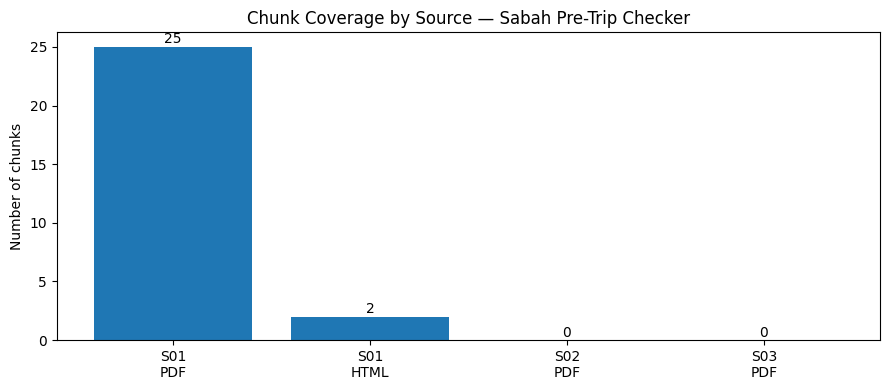


Domain coverage (keyword proxy):
    scope_group                    required_area  chunks
 Mount Kinabalu          Booking window / status       2
 Mount Kinabalu                      Daily quota       2
 Mount Kinabalu              Booking and payment       2
 Mount Kinabalu      Self check-in and documents       3
 Mount Kinabalu Fees (package and other charges)       8
 Mount Kinabalu     Date change and cancellation       5
 Mount Kinabalu          Registration on arrival      10
 Mount Kinabalu              Health restrictions       2
 Sipadan Island           Permit and daily limit       0
TAR Marine Park              Entry and park fees       0
 Entry to Sabah  Entry documents (East Malaysia)       0
  Seasonal risk                Northeast monsoon       0
  Seasonal risk                             Haze       0

Traveller category mentioned (keyword proxy):
traveller_category  chunks
         Malaysian       5
     International       5


In [ ]:
# Cell 6 — Coverage by source (including inventoried sources with 0 chunks)
#          + domain coverage against the V1 scope (keyword proxy)
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# 1) Source coverage --------------------------------------------------------
# Every source in the Week 3 data inventory is listed, so a source that was
# never processed appears as 0 instead of silently disappearing.
INVENTORY = [
    ('S01', 'sabahparks_mount_kinabalu_climbing.pdf',  'Sabah Parks (official)'),
    ('S01', 'sabahparks_mount_kinabalu_climbing.html', 'Sabah Parks (official)'),
    ('S02', 'sabahparks_terms_and_conditions.pdf',     'Sabah Parks (official)'),
    ('S03', 'gec_haze_safety_advisory.pdf',            'GEC (secondary, NGO)'),
]
source_counts = Counter(c.metadata.get('source', 'unknown') for c in unique_chunks)
coverage = pd.DataFrame([
    {'source_id': sid, 'source': src, 'owner': owner,
     'chunks': source_counts.get(src, 0),
     'percent': round(source_counts.get(src, 0) / len(unique_chunks) * 100, 1)}
    for sid, src, owner in INVENTORY
])
unknown = set(source_counts) - {src for _, src, _ in INVENTORY}
print(coverage.to_string(index=False))
print('Sources not in the inventory:', unknown or 'none')

plt.figure(figsize=(9, 4))
labels = coverage['source_id'] + '\n' + coverage['source'].str.rsplit('.', n=1).str[-1].str.upper()
plt.bar(labels, coverage['chunks'])
for x, n in enumerate(coverage['chunks']):
    plt.text(x, n + 0.3, str(n), ha='center')
plt.ylabel('Number of chunks')
plt.title('Chunk Coverage by Source — Sabah Pre-Trip Checker')
plt.tight_layout()
plt.savefig('/content/docs/week4_coverage_by_source.png', dpi=150)
plt.show()

# 2) Domain coverage against the V1 scope ------------------------------------
# PROXY: areas are assigned by keyword matching on the chunk text. This is not
# source metadata; a match only shows that the topic is mentioned.
AREAS = [
    # (scope group, required area, keyword regex)
    ('Mount Kinabalu', 'Booking window / status',        r'booking status|bookings? .*opened|climbing season'),
    ('Mount Kinabalu', 'Daily quota',                     r'climbers per day'),
    ('Mount Kinabalu', 'Booking and payment',             r'booking procedure|pay online|payment time|unpaid reservation'),
    ('Mount Kinabalu', 'Self check-in and documents',     r'self-check-in|documents to bring|indemnity'),
    ('Mount Kinabalu', 'Fees (package and other charges)', r'\brm ?\d'),
    ('Mount Kinabalu', 'Date change and cancellation',    r'date change|date-change|cancellation'),
    ('Mount Kinabalu', 'Registration on arrival',         r'arrive & register|permit tag|timpohon gate'),
    ('Mount Kinabalu', 'Health restrictions',             r'health restrictions|refrain from climbing'),
    ('Sipadan Island',  'Permit and daily limit',         r'sipadan'),
    ('TAR Marine Park', 'Entry and park fees',            r'tunku abdul rahman|marine park'),
    ('Entry to Sabah',  'Entry documents (East Malaysia)', r'immigration|entry permit|imm\.?13'),
    ('Seasonal risk',   'Northeast monsoon',              r'monsoon'),
    ('Seasonal risk',   'Haze',                           r'\bhaze\b|air pollutant index|air quality'),
]
texts = [c.page_content.lower() for c in unique_chunks]
domain = pd.DataFrame([
    {'scope_group': g, 'required_area': a,
     'chunks': sum(bool(re.search(p, t)) for t in texts)}
    for g, a, p in AREAS
])
print('\nDomain coverage (keyword proxy):')
print(domain.to_string(index=False))

# 3) Traveller category (RAI1) — mentions in the text, not user attributes -----
cat = pd.DataFrame([
    {'traveller_category': 'Malaysian',     'chunks': sum('malaysian' in t for t in texts)},
    {'traveller_category': 'International', 'chunks': sum('international' in t for t in texts)},
])
print('\nTraveller category mentioned (keyword proxy):')
print(cat.to_string(index=False))

domain.to_csv('/content/docs/week4_domain_coverage.csv', index=False)

**B2 reflection.** The least well supported areas are Sipadan Island and Tunku Abdul Rahman Marine Park, which are both V1 sites but have 0 chunks. This is a genuine coverage gap, not a difference in quantity: no official source for either site has been collected, so the system cannot support FR2 for them and must state that they are not covered (FR6). Entry documents for East Malaysia (FR8) and the northeast monsoon (FR5) are also genuine gaps for the same reason.

Two zero counts have a different cause. The booking terms (S02) and the haze advisory (S03) are in the Week 3 inventory but were not processed, because the Topic 3 pipeline was built for one source (S01). The evidence exists; it has not yet been prepared. This is a pipeline gap that can be closed by running the V2 pipeline on these files.

Within Mount Kinabalu, every required area appears in at least two chunks. The differences in counts (for example 2 chunks for health restrictions and 10 for registration on arrival) reflect how much text the page gives each topic, not missing evidence. The domain grouping is a keyword proxy, so a match shows only that a topic is mentioned. Finally, Malaysian and international travellers are each mentioned in 5 chunks, but equal mention counts do not show that the rules for each group are complete or correct. Whether the RAI1 threshold (recall gap ≤ 10 points) is met is not yet possible to determine from the data; it must be measured with the stratified evaluation set in a later week.


## **Step B3:** Identify bias risks, trace propagation, and define mitigations

### B3 — Bias risks, propagation and mitigations

| Bias type | Evidence | Likely origin | Potential downstream impact | Mitigation | Test |
|---|---|---|---|---|---|
| Historical bias | The corpus records the page at one point in time: "2026 package rates · price update: 25 November 2025" (chunk 4) and "As of 19 September 2026, bookings for the 2027 … season have not opened" (chunk 1). 5 chunks were flagged as time-sensitive in A2. | Source / historical condition: the official page is accurate for the date it was retrieved, but the rules and prices will change | After 2027 bookings open or the rates change, the system would state an outdated rule with an official citation, which looks more trustworthy than an unofficial answer (RAI5) | Keep the `time_sensitive` flag and the retrieval date in metadata; re-retrieve the page within the 90-day review period and compare its hash with the archived snapshot; show the last-checked date with every requirement | RAI5 test: rules with expired check dates are flagged (100%); Topic 8 scenario asking about 2027 bookings after the status changes |
| Representation bias | All 27 chunks come from one source owner (Sabah Parks) and one site (Mount Kinabalu). Sipadan, Tunku Abdul Rahman Marine Park, entry documents and the monsoon have 0 chunks (B2). | Both: source selection (no source collected for these areas) and pipeline (S02 and S03 are in the inventory but were not processed in Topic 3) | Questions about uncovered sites may retrieve unrelated Mount Kinabalu rules, or the model may fill the gap from general knowledge. International travellers are potentially more affected, because entry documents (FR8) are missing entirely: a potential RAI1 risk | Add at least one official source for each V1 site and for entry documents before Week 9; add a coverage check to the pipeline that holds the gate when a V1 site has no official source; answer "not covered" for such sites (FR6) | Topic 8 stratified scenario set by site and traveller category: requirement recall per group (gap ≤ 10 points, RAI1); out-of-coverage questions answered with "not covered" |
| Measurement bias | Saving the web page as a PDF flattened the fee tables. The International rows were cut from their column labels and hostel name (original chunk 3), the two breakdown tables were missing, and the 500-character chunk limit split 17 headings from their content (e.g. the dinner time) | Measurement / pipeline: the way the page was captured (PDF conversion) and chunked, not the source itself | A retrieved price or time can lose the labels that say whom or what it applies to, so the system may give the wrong fee to an international climber or the wrong time for an activity. The International fees were the rows most affected | Ingest web pages as HTML; verify every extracted table (Check A: rows appear in the source text; Check B: breakdown rows sum to the package price) before use; chunk by section heading in V2 | Topic 8 fee and timing questions for both traveller categories, checking the answer value and the cited sentence; keep the table negative test in the pipeline |

**B3 reflection.**

***Representation bias.*** The risk originates mainly in source selection, with the pipeline adding to it: only the Mount Kinabalu climbing guide has been collected and processed, while the booking terms (S02) and haze advisory (S03) were inventoried but not prepared. Travellers to Sipadan and Tunku Abdul Rahman Marine Park are affected, and potentially international travellers more than Malaysian travellers, because entry documents are not covered at all. The risk propagates because retrieval always returns the closest chunks it has: a question about Sipadan permits could retrieve Mount Kinabalu permit rules, and the generator could present them, or general knowledge, as if they applied. The pipeline can intervene at source collection (one official source per V1 site) and at validation (a coverage check that holds the gate). What must still be tested in Topic 8 is whether requirement recall differs between sites and between traveller categories, and whether the system refuses to answer for uncovered sites instead of inventing rules.

***Measurement bias.*** This risk was introduced by an engineering decision, not by the source: the official page shows complete tables, but saving it as a PDF and chunking it at a fixed length separated values from their labels. The fee rows for international climbers were the most affected, so this is a potential fairness risk as well as an accuracy risk. It propagates through retrieval, which can return a price without the row that says it is the international price, and through generation, which would then state that price confidently with a correct-looking citation. The pipeline can intervene at ingestion (read HTML), at transformation (verified table extraction and heading-aware chunking) and at validation (the R7 split-heading rule and the table negative test). Topic 8 must still test whether fee and time answers are correct for both traveller categories, because a clean dataset does not guarantee that retrieval selects the right chunk.

## **Step B4:** Review privacy, consent, rights/access, and data governance

In [ ]:
# Cell 7 — Personal-data scan (evidence for B4)
# Looks for patterns that could identify a person. Matches are listed for
# manual review: a phone number or email may belong to an organisation.
import re
import pandas as pd

PATTERNS = {
    'email':           r'[\w.+-]+@[\w-]+\.[\w.]+',
    'phone':           r'\+?6?0\s?\d{1,2}[-\s]?\d{3,4}\s?\d{3,4}',
    'mykad_number':    r'\b\d{6}-\d{2}-\d{4}\b',
    'passport_number': r'\b[A-Z]{1,2}\d{7,8}\b',
}
hits = []
for i, c in enumerate(unique_chunks):
    for kind, pat in PATTERNS.items():
        for m in re.finditer(pat, c.page_content):
            s = max(0, m.start() - 60)
            hits.append({'chunk_id': i, 'type': kind, 'match': m.group(),
                         'context': c.page_content[s:m.end() + 20].replace('\n', ' ')})
privacy_df = pd.DataFrame(hits, columns=['chunk_id', 'type', 'match', 'context'])
print(privacy_df.groupby('type').size().reindex(PATTERNS.keys(), fill_value=0))
pd.set_option('display.max_colwidth', 110)
print(privacy_df.to_string(index=False))
privacy_df.to_csv('/content/docs/week4_privacy_scan.csv', index=False)

type
email              1
phone              3
mykad_number       0
passport_number    0
dtype: int64
 chunk_id  type                   match                                                                                                 context
       25 phone           +60 88-201564            team for eligibility, date changes and booking questions.  +60 88-201564 Email reservations 
       26 email hello@sabahparks.org.my a Kinabalu, Sabah, Malaysia.  Phone : +6088-523500  Email : hello@sabahparks.org.my  S U P P O R T  P R
       26 phone           +60 88-273238                                                                       +60 88-273238 Email technical sup
       26 phone            +6088-523500            , KK Times Square, Kota Kinabalu, Sabah, Malaysia.  Phone : +6088-523500  Email : hello@saba


### B4 — Privacy, consent, rights/access and data governance

| Governance question | Evidence from your project | Status | Required action / owner |
|---|---|---|---|
| Are the source owner, version/date, and provenance traceable? | Every chunk has `source`, `record_id` and `source_sha256`; R2 and R3 passed for all chunks; the PDF snapshot was retrieved 2026-11-08 (page "Last Updated: 8 November 2026") and the HTML snapshot 2026-11-25 07:15:17 UTC with its SHA-256 recorded. However, the corpus mixes two snapshots of S01: 25 chunks from the PDF and 2 records from the HTML | OK for traceability; Gap for version consistency | Rebuild all S01 chunks from one HTML snapshot in V2 and record a single retrieval date per source / Tan Qian Hui, before Week 9 |
| Are rights/access terms known and appropriate for intended use? | All three sources are publicly accessible, but each owner states "all rights reserved"; no licence or written permission has been obtained. robots.txt allows the HTML retrieval. The raw copies are used only for non-commercial educational analysis, are not altered, and are attributed to their owners in `data/README.md`, which also commits to removal on request. The root README, however, states that such documents are referenced by URL only and not committed | To verify (decision: proceed with conditions) | Keep the raw copies under the existing conditions (attribution, non-commercial use, unchanged copies, removal on request); update the root README so that it matches `data/README.md`; add the HTML snapshot to `data/README.md` / Tan Qian Hui, Part C commit |
| Does the corpus contain personal or sensitive data that is unnecessary for the task? | Cell 7 scan: 0 MyKad or passport numbers; 1 email and 3 phone numbers, all organisational contacts of Sabah Parks and its booking service (chunks 25–26) | No | Keep the organisational contacts, which support FR3 redirects; re-run the scan whenever a new source is added / Tan Qian Hui |
| If personal data is collected, is the collection basis / consent / disclosure appropriate? | The corpus contains only public institutional documents, so consent does not apply to the data. User input is a separate issue: RAI6 limits the system to collecting the traveller category and forbids sending identity numbers to external model APIs | N/A for the corpus | Test RAI6 (identity numbers in prompts are not sent to the API) when the input stage is built / Tan Qian Hui, Topic 8 |
| Are update, superseded-version, retention, or removal responsibilities defined? | RAI5 sets a 90-day review period; time-sensitive chunks are flagged; raw snapshots are kept in `data/raw/` with hashes for change detection; `data/README.md` commits to removal on request. No procedure yet defines what happens to old chunks when a source changes | Gap | Define the update procedure: re-retrieve within 90 days, compare hashes, rebuild the source's chunks and archive the superseded snapshot with its dates / Tan Qian Hui, V2 pipeline |

# **Part C - Data Quality, Bias, and Responsible Data Report**

The evidence from Parts A and B is consolidated in [`docs/week4_data_quality_report.md`](../docs/week4_data_quality_report.md).

**Topic 4 quality gate decision: GO WITH CONDITIONS — for Mount Kinabalu only.** The reviewed corpus (`data/prepared_chunks_clean.jsonl`, `data/chunks_clean.pkl`; 27 chunks) is traceable, contains no duplicates or personal data, and its fee tables have been verified against the source. Sipadan Island, Tunku Abdul Rahman Marine Park, entry documents and the monsoon must be answered as "not covered" until official sources are added, and the V2 pipeline (HTML ingestion, heading-aware chunking) must be built and re-checked with the Topic 4 rules before Week 9.